In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.2/95.2 kB 10.0 MB/s eta 0:00:00


In [4]:
from pathlib import Path
from ultralytics import YOLO

DATA_CONFIG = '/content/drive/MyDrive/config.yaml'

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [5]:
# Model Training
model = YOLO('yolo26s-pose.pt')

results = model.train(
    data=DATA_CONFIG,

    # Core settings
    imgsz=1024,
    epochs=50,
    patience=15,
    batch=16,
    workers=8,

    # Viewpoint & geometry
    degrees=10.0,
    perspective=0.001,
    shear=5.0,
    translate=0.03,
    fliplr=0.5,
    flipud=0.0,

    # Controlled lighting
    hsv_h=0.015,
    hsv_s=0.1,
    hsv_v=0.2,

    close_mosaic=10
)

Ultralytics 8.4.171 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/config.yaml, degrees=10.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.1, hsv_v=0.2, imgsz=1024, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s-pose.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=Fa

In [6]:
# Copy the runs directory to Google Drive with progress status
!rsync -av --progress /content/runs "/content/drive/My Drive/"

sending incremental file list
runs/
runs/pose/
runs/pose/train/
runs/pose/train/BoxF1_curve.png
         98,694 100%   62.87MB/s    0:00:00 (xfr#1, to-chk=28/32)
runs/pose/train/BoxPR_curve.png
         73,799 100%   11.73MB/s    0:00:00 (xfr#2, to-chk=27/32)
runs/pose/train/BoxP_curve.png
         81,597 100%    3.11MB/s    0:00:00 (xfr#3, to-chk=26/32)
runs/pose/train/BoxR_curve.png
         97,385 100%    2.32MB/s    0:00:00 (xfr#4, to-chk=25/32)
runs/pose/train/PoseF1_curve.png
         98,694 100%    1.62MB/s    0:00:00 (xfr#5, to-chk=24/32)
runs/pose/train/PosePR_curve.png
         73,799 100%  889.74kB/s    0:00:00 (xfr#6, to-chk=23/32)
runs/pose/train/PoseP_curve.png
         81,597 100%  711.47kB/s    0:00:00 (xfr#7, to-chk=22/32)
runs/pose/train/PoseR_curve.png
         97,385 100%  766.96kB/s    0:00:00 (xfr#8, to-chk=21/32)
runs/pose/train/args.yaml
          1,658 100%   13.06kB/s    0:00:00 (xfr#9, to-chk=20/32)
runs/pose/train/confusion_matrix.png
         90,742 100%  6

In [7]:
# Load your model and run validation
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2

# Load best model
model = YOLO("/content/drive/My Drive/runs/pose/train/weights/best.pt")

# Run validation on your dataset
metrics = model.val()

# Extract and display summary metrics
print(" BOX DETECTION METRICS ")
print(f"Box mAP50-95 : {metrics.box.map:.4f}")
print(f"Box mAP50    : {metrics.box.map50:.4f}")
print(f"Box mAP75    : {metrics.box.map75:.4f}")

print(f"Box Precision: {metrics.box.mp:.4f}")
print(f"Box Recall   : {metrics.box.mr:.4f}")

print("\n POSE ESTIMATION METRICS ")
print(f"Pose mAP50-95: {metrics.pose.map:.4f}")
print(f"Pose mAP50   : {metrics.pose.map50:.4f}")
print(f"Pose mAP75   : {metrics.pose.map75:.4f}")

print(f"Pose Precision: {metrics.pose.mp:.4f}")
print(f"Pose Recall   : {metrics.pose.mr:.4f}")

Ultralytics 8.4.171 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s-pose summary (fused): 129 layers, 9,941,157 parameters, 0 gradients, 22.5 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.1 ms, read: 331.1±49.7 MB/s, size: 919.0 KB)
val: Scanning /content/drive/.shortcut-targets-by-id/1j7jT2m5fLVI8vtW79ZG2L6nNtb3POZmF/data/labels/val.cache... 527 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 527/527 138.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 33/33 1.3it/s 25.4s
                   all        527        527          1      0.998      0.995      0.716          1      0.998      0.995      0.778
Speed: 5.3ms preprocess, 25.1ms inference, 0.0ms loss, 2.3ms postprocess per image
Results saved to /content/runs/pose/val
 BOX DETECTION METRICS 
Box mAP50-95 : 0.7163
Box mAP50    : 0.9950
Box mAP75    : 0.8556
Box Precision: 0.9998
Box Recall  

# Ground Truth Vs Model Prediction Batches


image 1/1 /content/drive/My Drive/data/images/val/20211013_1-4_1050.jpg: 768x1024 1 rat, 28.7ms
Speed: 21.9ms preprocess, 28.7ms inference, 11.0ms postprocess per image at shape (1, 3, 768, 1024)


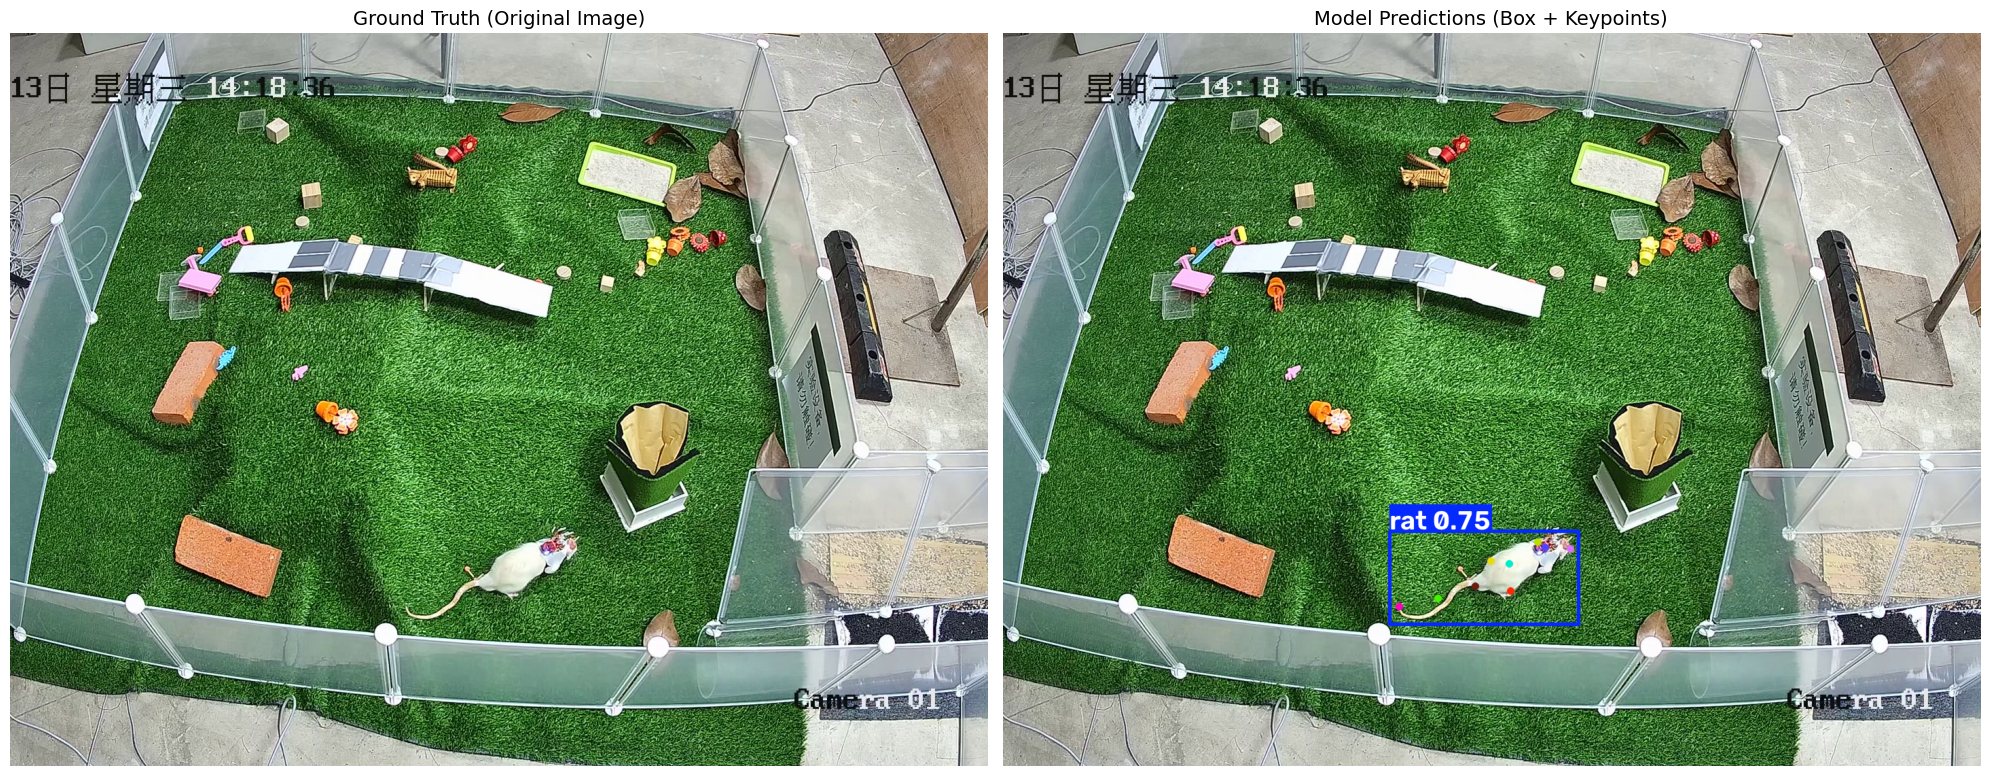

In [10]:
import os
import glob
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

val_dir = "/content/drive/My Drive/data/images/val"

image_paths = glob.glob(os.path.join(val_dir, "*.[jJ][pP][gG]")) + \
              glob.glob(os.path.join(val_dir, "*.[pP][nN][gG]"))

if image_paths:
    test_img_path = image_paths[0]

    orig_img = cv2.imread(test_img_path)
    orig_rgb = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)

    results = model.predict(source=test_img_path, conf=0.5, imgsz=1024)
    pred_img = results[0].plot()
    pred_rgb = cv2.cvtColor(pred_img, cv2.COLOR_BGR2RGB)

    fig, axes = plt.subplots(1, 2, figsize=(20, 10))

    axes[0].imshow(orig_rgb)
    axes[0].set_title("Ground Truth (Original Image)", fontsize=14)
    axes[0].axis('off')

    axes[1].imshow(pred_rgb)
    axes[1].set_title("Model Predictions (Box + Keypoints)", fontsize=14)
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

# Box mAP Vs Pose mAP Comparison

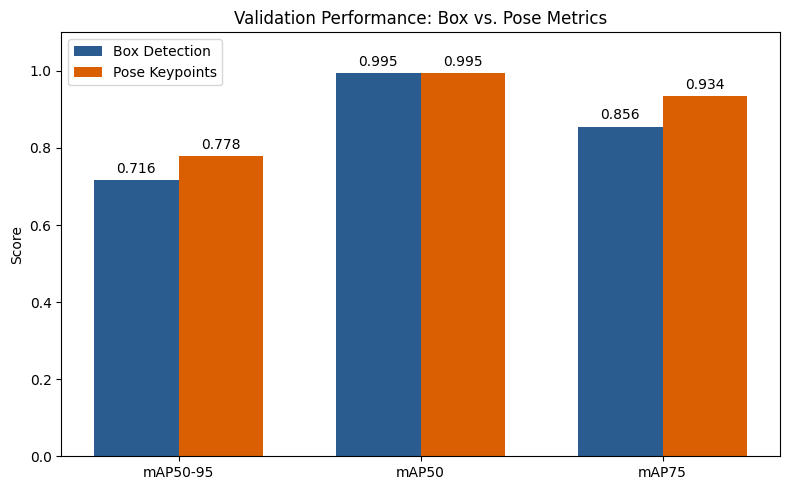

In [11]:
import numpy as np

labels = ['mAP50-95', 'mAP50', 'mAP75']
box_scores = [metrics.box.map, metrics.box.map50, metrics.box.map75]
pose_scores = [metrics.pose.map, metrics.pose.map50, metrics.pose.map75]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, box_scores, width, label='Box Detection', color='#2b5c8f')
rects2 = ax.bar(x + width/2, pose_scores, width, label='Pose Keypoints', color='#d95f02')

ax.set_ylabel('Score')
ax.set_title('Validation Performance: Box vs. Pose Metrics')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1.1)
ax.legend()

ax.bar_label(rects1, padding=3, fmt='%.3f')
ax.bar_label(rects2, padding=3, fmt='%.3f')

plt.tight_layout()
plt.show()

# Results

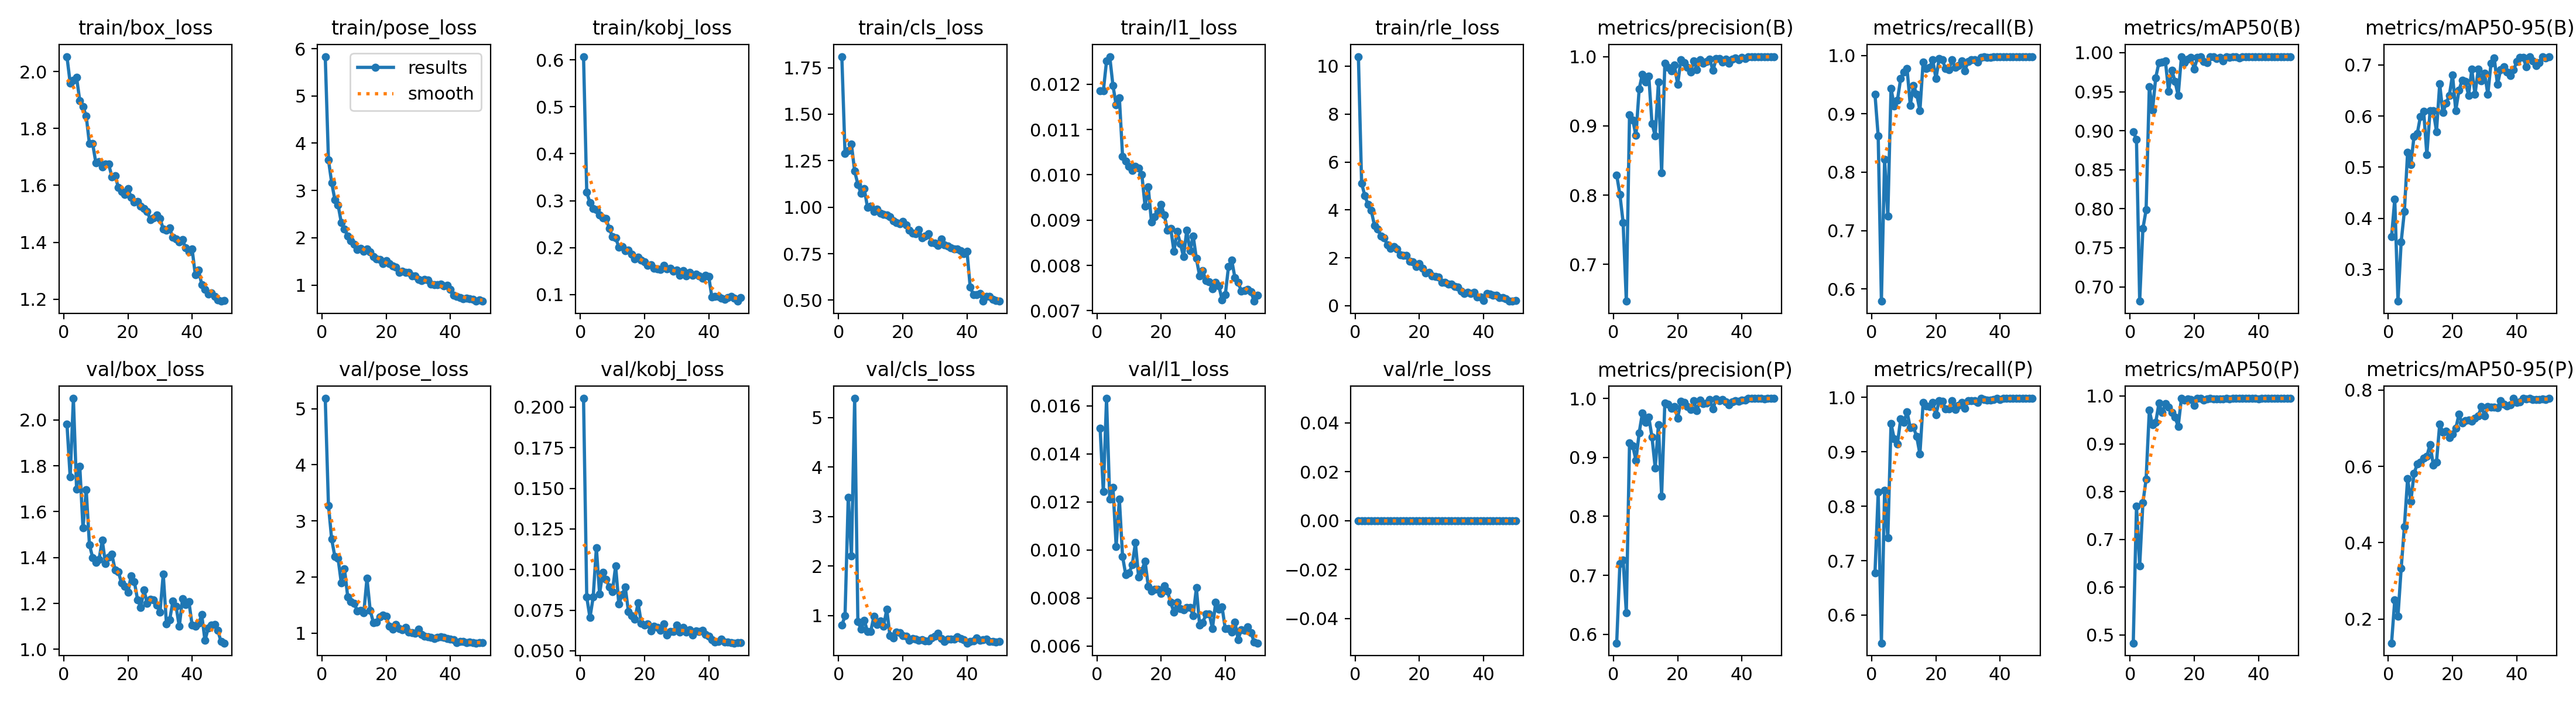